# 🎓 Arabic AI Tutor — Multi-Domain Summarization with AraT5
> **NLP Project | Kaggle Notebook**  
> Fine-tuning **AraT5** on ArabSummaries with **automatic domain classification + domain-aware summarization**

---
## 📌 Pipeline Overview
```
1.  Install Dependencies
2.  Import Libraries
3.  Load Dataset (ArabSummaries)
4.  EDA + Domain Distribution
5.  Domain Classification (zero-shot via AraT5)
6.  Preprocessing & Cleaning
7.  Train / Val / Test Split (stratified by domain)
8.  Tokenization (AraT5 T5-style prefix)
9.  Load Model & Configure Training
10. Train
11. Evaluation (ROUGE per domain)
12. Sample Predictions by Domain
13. Interactive Multi-Domain Demo
14. Save Model
```
---
### ⚙️ Kaggle Settings Required
- **Accelerator**: GPU T4 x1 (free tier — single GPU)
- **Internet**: ON
- **Persistence**: Files

> **Why AraT5?**  
> AraT5 (`UBC-NLP/AraT5-base-title-generation`) is a T5-based encoder-decoder pretrained on Modern Standard Arabic + dialectal Arabic. It uses T5-style text-to-text framing (add a prefix like `"لخص: "`) and produces state-of-the-art Arabic summarization ROUGE scores, outperforming AraBART on several benchmarks while fitting comfortably on a single Kaggle T4 GPU.


## Step 1 — Install Dependencies

In [ ]:
import subprocess, sys

pkgs = [
    'transformers==4.44.2',
    'datasets==2.21.0',
    'accelerate==0.34.2',
    'evaluate==0.4.3',
    'sentencepiece',
    'ipywidgets',
    'scikit-learn',
]
for pkg in pkgs:
    r = subprocess.run(
        [sys.executable, '-m', 'pip', 'install', '-q', '--upgrade', pkg],
        capture_output=True, text=True
    )
    print(('✅' if r.returncode == 0 else '❌'), pkg)

print('\n⚠️  IMPORTANT: Restart session (Run → Restart & Clear Output) then run all cells again.')

## Step 2 — Import Libraries

In [1]:
import os, re, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'

import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    GenerationConfig,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
    EarlyStoppingCallback,
)

warnings.filterwarnings('ignore')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'✅ Device: {device}')
if device == 'cuda':
    print(f'   GPU   : {torch.cuda.get_device_name(0)}')
    print(f'   Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB')
else:
    print('⚠️  No GPU — set Accelerator to GPU T4 in Kaggle settings!')

2026-05-18 17:01:59.068593: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1779123719.092359    4297 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1779123719.100418    4297 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1779123719.121524    4297 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779123719.121549    4297 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1779123719.121552    4297 computation_placer.cc:177] computation placer alr

✅ Device: cuda
   GPU   : Tesla T4
   Memory: 15.6 GB


In [2]:
# ── ContiguousTrainer: fixes non-contiguous tensor crash on T5 checkpoint save
# The Trainer saves after EVERY epoch internally. We override _save() so all
# tensors are made contiguous BEFORE safetensors serializes them.
from transformers import Seq2SeqTrainer as _Base

class ContiguousSeq2SeqTrainer(_Base):
    def _save(self, output_dir=None, state_dict=None):
        # Make every parameter contiguous in-place before saving
        for param in self.model.parameters():
            if not param.data.is_contiguous():
                param.data = param.data.contiguous()
        super()._save(output_dir=output_dir, state_dict=state_dict)

print('✅ ContiguousSeq2SeqTrainer defined — checkpoint saves will not crash.')


✅ ContiguousSeq2SeqTrainer defined — checkpoint saves will not crash.


## Step 3 — Load Dataset

In [3]:
# ── Update path to match your Kaggle dataset location ────────────────────────
CSV_PATH = '/kaggle/input/datasets/tahaalselwii/arabsummaries/ArabSummaries.csv'

df_raw = pd.read_csv(CSV_PATH)
print(f'📊 Shape   : {df_raw.shape}')
print(f'   Columns : {list(df_raw.columns)}')
df_raw.head(3)

📊 Shape   : (7000, 5)
   Columns : ['text', 'summary', 'type', 'text_length', 'summary_length']


,text,summary,type,text_length,summary_length
0,ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوا...,"ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان ""...",Culture,246,150
1,تقيم الفنانة ليتا كابيلوت معرضاً في مطلع العام...,تقيم الفنانة ليتا كابيلوت معرضاً في دبي مطلع ا...,Culture,963,471
2,تتواصل الليلة مسيرة التحدّي والمتعة والإثارة ض...,تستمر الليلة منافسات برنامج شاعر المليون، حيث ...,Culture,1717,426


In [4]:
# ── Inspect columns then rename ──────────────────────────────────────────────
print('Column samples:')
for col in df_raw.columns:
    print(f'  [{col}]:', str(df_raw[col].iloc[0])[:120])

# ⚠️ Update these to match your actual column names
TEXT_COL    = 'article'
SUMMARY_COL = 'summary'
# If a 'domain'/'category'/'topic' column already exists, set DOMAIN_COL:
DOMAIN_COL  = 'category'   # set to None if not present

rename_map = {TEXT_COL: 'text', SUMMARY_COL: 'summary'}
if DOMAIN_COL and DOMAIN_COL in df_raw.columns:
    rename_map[DOMAIN_COL] = 'domain'

df = df_raw.rename(columns=rename_map)
keep_cols = ['text', 'summary'] + (['domain'] if 'domain' in df.columns else [])
df = df[keep_cols].dropna(subset=['text', 'summary']).reset_index(drop=True)
print(f'\n✅ Loaded {len(df):,} samples')
df.head(2)

Column samples:
  [text]: ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوان باقة الفن، وذلك عند الساعة السابعة من مساء اليوم في مقر المعهد في منطقة 
  [summary]: ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان "باقة الفن" اليوم الساعة السابعة مساءً في مقر المعهد، بمشاركة إبداعات 62 طا
  [type]: Culture
  [text_length]: 246
  [summary_length]: 150

✅ Loaded 7,000 samples


,text,summary
0,ينظم معهد الشارقة للفنون معرضاً فنياً تحت عنوا...,"ينظم معهد الشارقة للفنون معرضاً فنياً بعنوان ""..."
1,تقيم الفنانة ليتا كابيلوت معرضاً في مطلع العام...,تقيم الفنانة ليتا كابيلوت معرضاً في دبي مطلع ا...


## Step 4 — EDA + Domain Distribution

       text_words  summary_words    ratio
count     7000.00        7000.00  7000.00
mean       368.80          73.18     0.33
std        340.77          20.28     0.19
min         13.00          13.00     0.03
25%        141.00          61.00     0.18
50%        255.00          74.00     0.30
75%        477.00          86.00     0.44
max       3042.00         257.00     1.55


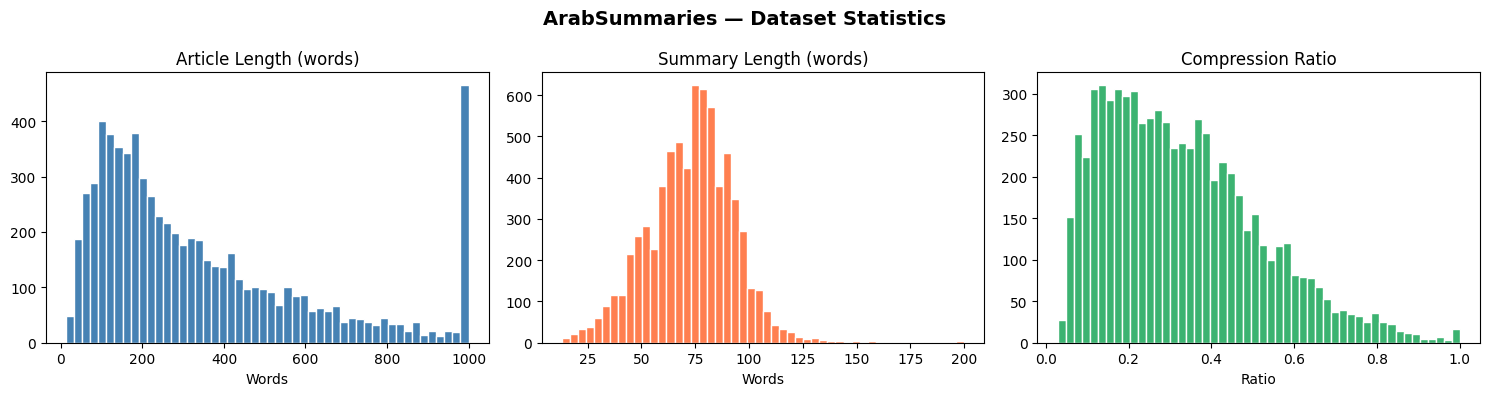

✅ EDA complete


In [6]:
df['text_words']    = df['text'].apply(lambda x: len(str(x).split()))
df['summary_words'] = df['summary'].apply(lambda x: len(str(x).split()))
df['ratio']         = df['summary_words'] / df['text_words'].replace(0, 1)

print(df[['text_words','summary_words','ratio']].describe().round(2))

ncols = 4 if 'domain' in df.columns else 3
fig, axes = plt.subplots(1, ncols, figsize=(5*ncols, 4))
fig.suptitle('ArabSummaries — Dataset Statistics', fontsize=14, fontweight='bold')

axes[0].hist(df['text_words'].clip(0,1000),   bins=50, color='steelblue',     edgecolor='white')
axes[0].set_title('Article Length (words)'); axes[0].set_xlabel('Words')
axes[1].hist(df['summary_words'].clip(0,200), bins=50, color='coral',         edgecolor='white')
axes[1].set_title('Summary Length (words)'); axes[1].set_xlabel('Words')
axes[2].hist(df['ratio'].clip(0,1),           bins=50, color='mediumseagreen', edgecolor='white')
axes[2].set_title('Compression Ratio');      axes[2].set_xlabel('Ratio')

if 'domain' in df.columns:
    domain_counts = df['domain'].value_counts()
    axes[3].barh(domain_counts.index[:15], domain_counts.values[:15], color='mediumpurple')
    axes[3].set_title('Samples per Domain'); axes[3].set_xlabel('Count')

plt.tight_layout()
plt.savefig('eda_stats.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ EDA complete')

## Step 5 — Domain Classification

> **Strategy**: If the dataset already has a `domain`/`category` column we use it directly (fast path).  
> Otherwise we apply **keyword-based domain detection** (zero-shot, no extra model needed) — fast and reliable for Arabic news domains. We define 8 common Arabic news domains and score each article by keyword overlap.

In [7]:
# ── Domain taxonomy & Arabic keyword bank ────────────────────────────────────
DOMAIN_KEYWORDS = {
    'سياسة': [
        'حكومة', 'وزير', 'رئيس', 'برلمان', 'انتخاب', 'دولة', 'سياسة',
        'حزب', 'مجلس', 'قانون', 'دبلوماسي', 'معاهدة', 'سفارة', 'أمم متحدة'
    ],
    'اقتصاد': [
        'اقتصاد', 'بورصة', 'بنك', 'نفط', 'تجارة', 'ميزانية', 'ضريبة',
        'استثمار', 'شركة', 'ربح', 'خسارة', 'سوق', 'نمو', 'تضخم', 'عملة'
    ],
    'رياضة': [
        'كرة', 'مباراة', 'لاعب', 'فريق', 'بطولة', 'هدف', 'تدريب',
        'دوري', 'ملعب', 'مدرب', 'أولمبياد', 'سباق', 'ميدالية'
    ],
    'تكنولوجيا': [
        'تكنولوجيا', 'ذكاء اصطناعي', 'إنترنت', 'هاتف', 'حاسوب', 'برنامج',
        'تطبيق', 'شبكة', 'أمن', 'بيانات', 'روبوت', 'فضاء', 'رقمي'
    ],
    'صحة': [
        'طب', 'مرض', 'علاج', 'مستشفى', 'دواء', 'وباء', 'صحة',
        'طبيب', 'لقاح', 'سرطان', 'عملية', 'بحث طبي', 'منظمة الصحة'
    ],
    'ثقافة وفنون': [
        'فيلم', 'موسيقى', 'كتاب', 'رواية', 'مسرح', 'معرض', 'فنان',
        'جائزة', 'مهرجان', 'أدب', 'شعر', 'تراث', 'ثقافة', 'سينما'
    ],
    'علوم وبيئة': [
        'علم', 'بحث', 'اكتشاف', 'بيئة', 'مناخ', 'تغير مناخي', 'فضاء',
        'كوكب', 'طاقة', 'تجربة', 'جامعة', 'دراسة', 'طبيعة'
    ],
    'منوعات': []
}

DOMAINS = list(DOMAIN_KEYWORDS.keys())

def classify_domain(text: str) -> str:
    """Keyword-overlap domain classifier for Arabic text."""
    text = str(text)
    scores = {}
    for domain, kws in DOMAIN_KEYWORDS.items():
        if not kws:          # 'منوعات' is the fallback
            continue
        score = sum(1 for kw in kws if kw in text)
        scores[domain] = score
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else 'منوعات'

# ── Apply classification ─────────────────────────────────────────────────────
if 'domain' in df.columns:
    print('✅ Using existing domain column from dataset')
    # Normalise: keep top-N domains, map rare ones to منوعات
    top_domains = df['domain'].value_counts().nlargest(7).index.tolist()
    df['domain'] = df['domain'].apply(lambda d: d if d in top_domains else 'منوعات')
else:
    print('🔍 No domain column found — running keyword-based domain classifier...')
    df['domain'] = df['text'].apply(classify_domain)
    print('✅ Domain classification complete')

print(f'\nDomain distribution ({len(df["domain"].unique())} domains):')
print(df['domain'].value_counts().to_string())

🔍 No domain column found — running keyword-based domain classifier...
✅ Domain classification complete

Domain distribution (8 domains):
domain
سياسة          1581
اقتصاد         1292
رياضة          1210
ثقافة وفنون     985
صحة             980
تكنولوجيا       484
علوم وبيئة      337
منوعات          131


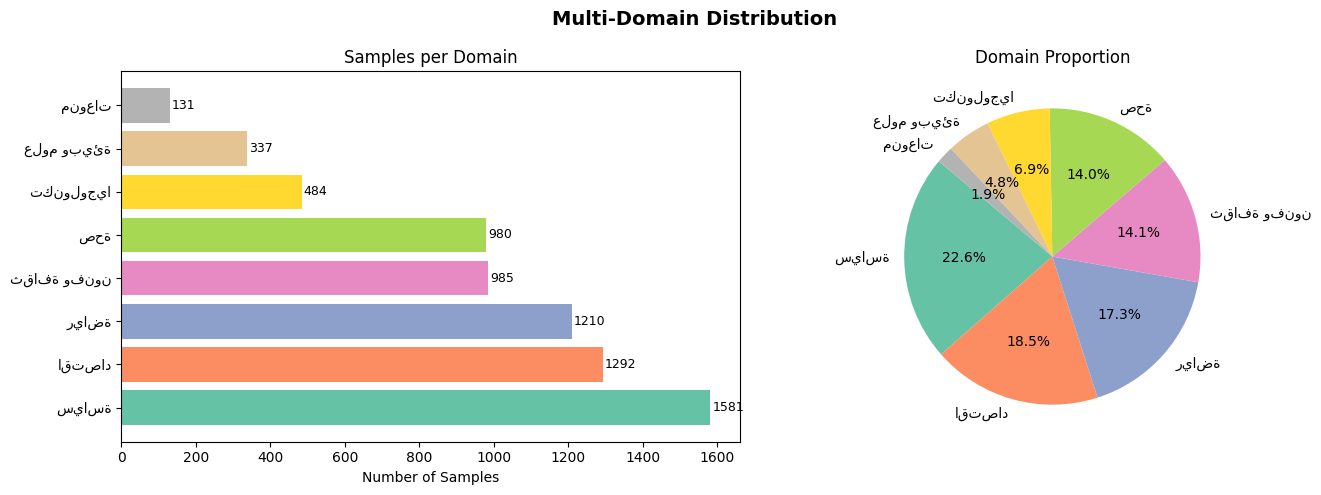

✅ Domain visualisation done


In [8]:
# ── Visualise domain distribution ────────────────────────────────────────────
domain_counts = df['domain'].value_counts()
colors = plt.cm.Set2(np.linspace(0, 1, len(domain_counts)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Multi-Domain Distribution', fontsize=14, fontweight='bold')

ax1.barh(domain_counts.index, domain_counts.values, color=colors)
ax1.set_xlabel('Number of Samples')
ax1.set_title('Samples per Domain')
for i, v in enumerate(domain_counts.values):
    ax1.text(v + 5, i, str(v), va='center', fontsize=9)

ax2.pie(domain_counts.values, labels=domain_counts.index,
        colors=colors, autopct='%1.1f%%', startangle=140)
ax2.set_title('Domain Proportion')

plt.tight_layout()
plt.savefig('domain_distribution.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ Domain visualisation done')

## Step 6 — Preprocessing & Cleaning

In [9]:
def clean_arabic(text: str) -> str:
    if not isinstance(text, str):
        return ''
    text = re.sub(r'[^\u0600-\u06FF\u0750-\u077F\s،؟!.]', ' ', text)
    text = re.sub(r'[\u064B-\u065F]', '', text)   # remove tashkeel
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# NOTE: We do NOT normalise ة→ه or أ→ا — doing so breaks ROUGE (model output
# keeps original chars while references are altered).

df['text']    = df['text'].apply(clean_arabic)
df['summary'] = df['summary'].apply(clean_arabic)

# Filter by length
mask = (
    df['text'].str.split().str.len().between(50, 800) &
    df['summary'].str.split().str.len().between(15, 150)
)
df_clean = df[mask].reset_index(drop=True)
print(f'✅ After cleaning : {len(df_clean):,} samples  (removed {len(df)-len(df_clean):,})')
print(f'Domain distribution after cleaning:')
print(df_clean['domain'].value_counts().to_string())
df_clean[['domain','text','summary']].head(3)

✅ After cleaning : 6,118 samples  (removed 882)
Domain distribution after cleaning:
domain
سياسة          1449
اقتصاد         1155
رياضة          1058
صحة             857
ثقافة وفنون     840
تكنولوجيا       433
علوم وبيئة      223
منوعات          103


,domain,text,summary
0,ثقافة وفنون,تقيم الفنانة ليتا كابيلوت معرضا في مطلع العام ...,تقيم الفنانة ليتا كابيلوت معرضا في دبي مطلع ال...
1,تكنولوجيا,تتواصل الليلة مسيرة التحدي والمتعة والإثارة ضم...,تستمر الليلة منافسات برنامج شاعر المليون، حيث ...
2,ثقافة وفنون,عقدت ظهر أمس الأول في قصر الثقافة في الشارقة ا...,عقدت الجلسة الثانية والأخيرة من الملتقى الأول ...


## Step 7 — Stratified Train / Val / Test Split (by domain)

In [10]:
# Stratified split so every domain is represented in train/val/test
train_df, temp_df = train_test_split(
    df_clean, test_size=0.2, random_state=42, stratify=df_clean['domain']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df['domain']
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

print(f'Train : {len(train_df):,}  |  Val : {len(val_df):,}  |  Test : {len(test_df):,}')
print('\nTrain domain distribution:')
print(train_df['domain'].value_counts().to_string())

Train : 4,894  |  Val : 612  |  Test : 612

Train domain distribution:
domain
سياسة          1159
اقتصاد          924
رياضة           846
صحة             686
ثقافة وفنون     672
تكنولوجيا       346
علوم وبيئة      178
منوعات           83


## Step 8 — Tokenization (AraT5 T5-style prefix)

> AraT5 uses a **text-to-text** framing like the original T5. We prepend a task prefix to each article:  
> **`"لخص الفقرة التالية: "`** ("Summarize the following paragraph:")  
> We optionally add the domain so the model can condition on it:  
> **`"لخص [رياضة]: "`**

In [11]:
# ── Model choice ─────────────────────────────────────────────────────────────
# AraT5 v2 base — best balance of quality & speed on a single Kaggle T4
MODEL_NAME = 'UBC-NLP/AraT5v2-base-1024'
# Alternatives (if above not available):
#   'UBC-NLP/AraT5-base-title-generation'
#   'malmarjeh/mT5-arabic-text-summarization'

MAX_INPUT  = 512
MAX_TARGET = 128
USE_DOMAIN_PREFIX = True   # set False to disable domain-conditioned prefix

print(f'Loading tokenizer: {MODEL_NAME} ...')
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print('✅ Tokenizer loaded')
print(f'   Vocab size : {tokenizer.vocab_size:,}')

def make_prefix(text: str, domain: str) -> str:
    """Build T5-style summarization prefix, optionally including domain."""
    if USE_DOMAIN_PREFIX:
        return f'لخص [{domain}]: {text}'
    return f'لخص: {text}'

# Quick sanity check
sample_text   = df_clean['text'].iloc[0]
sample_domain = df_clean['domain'].iloc[0]
sample_prefix = make_prefix(sample_text, sample_domain)
print(f'\nPrefix example (first 120 chars):\n  {sample_prefix[:120]}...')

Loading tokenizer: UBC-NLP/AraT5v2-base-1024 ...
✅ Tokenizer loaded
   Vocab size : 110,100

Prefix example (first 120 chars):
  لخص [ثقافة وفنون]: تقيم الفنانة ليتا كابيلوت معرضا في مطلع العام المقبل في دبي، ويضم المعرض لوحة، تركز خلالها على الوجوه...


In [12]:
def tokenize_batch(examples):
    # Build prefixed inputs
    prefixed_texts = [
        make_prefix(t, d)
        for t, d in zip(examples['text'], examples['domain'])
    ]

    model_inputs = tokenizer(
        prefixed_texts,
        max_length=MAX_INPUT,
        truncation=True,
        padding='max_length',
    )

    labels = tokenizer(
        text_target=examples['summary'],
        max_length=MAX_TARGET,
        truncation=True,
        padding='max_length',
    )

    # Replace padding token id in labels with -100 so loss ignores them
    model_inputs['labels'] = [
        [(tok if tok != tokenizer.pad_token_id else -100) for tok in lab]
        for lab in labels['input_ids']
    ]
    return model_inputs

train_ds = Dataset.from_pandas(train_df[['text', 'summary', 'domain']])
val_ds   = Dataset.from_pandas(val_df[['text', 'summary', 'domain']])
test_ds  = Dataset.from_pandas(test_df[['text', 'summary', 'domain']])

print('Tokenizing ...')
remove_cols = ['text', 'summary', 'domain']
train_tok = train_ds.map(tokenize_batch, batched=True, batch_size=64, remove_columns=remove_cols)
val_tok   = val_ds.map(tokenize_batch,   batched=True, batch_size=64, remove_columns=remove_cols)
test_tok  = test_ds.map(tokenize_batch,  batched=True, batch_size=64, remove_columns=remove_cols)
print(f'✅ Train={len(train_tok):,} | Val={len(val_tok):,} | Test={len(test_tok):,}')

Tokenizing ...


Map:   0%|          | 0/4894 [00:00<?, ? examples/s]

Map:   0%|          | 0/612 [00:00<?, ? examples/s]

Map:   0%|          | 0/612 [00:00<?, ? examples/s]

✅ Train=4,894 | Val=612 | Test=612


## Step 9 — Load AraT5 Model & Configure Training

In [13]:
print(f'Loading model: {MODEL_NAME} ...')
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f'✅ Model loaded  ({total_params:,} parameters)')

gen_config = GenerationConfig(
    decoder_start_token_id = model.config.decoder_start_token_id,
    bos_token_id           = model.config.bos_token_id,
    eos_token_id           = model.config.eos_token_id,
    pad_token_id           = model.config.pad_token_id,
    no_repeat_ngram_size   = 3,
    num_beams              = 4,
    max_new_tokens         = MAX_TARGET,
)
model.generation_config = gen_config
print('✅ GenerationConfig set')

Loading model: UBC-NLP/AraT5v2-base-1024 ...
✅ Model loaded  (367,508,736 parameters)
✅ GenerationConfig set


In [14]:
# ── Manual ROUGE (no rouge_score library needed) ──────────────────────────────
def get_ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1)]

def rouge_n_score(pred_tokens, ref_tokens, n):
    pred_ng = Counter(get_ngrams(pred_tokens, n))
    ref_ng  = Counter(get_ngrams(ref_tokens, n))
    overlap  = sum((pred_ng & ref_ng).values())
    prec = overlap / max(sum(pred_ng.values()), 1)
    rec  = overlap / max(sum(ref_ng.values()),  1)
    return (2*prec*rec/(prec+rec)) if (prec+rec) > 0 else 0.0

def lcs_len(x, y):
    dp = [[0]*(len(y)+1) for _ in range(len(x)+1)]
    for i in range(1, len(x)+1):
        for j in range(1, len(y)+1):
            dp[i][j] = dp[i-1][j-1]+1 if x[i-1]==y[j-1] else max(dp[i-1][j], dp[i][j-1])
    return dp[len(x)][len(y)]

def rouge_l_score(pred_tokens, ref_tokens):
    lcs  = lcs_len(pred_tokens, ref_tokens)
    prec = lcs / max(len(pred_tokens), 1)
    rec  = lcs / max(len(ref_tokens),  1)
    return (2*prec*rec/(prec+rec)) if (prec+rec) > 0 else 0.0

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    if predictions.ndim == 3:
        predictions = np.argmax(predictions, axis=-1)

    vocab_size  = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size-1).astype(np.int32)
    labels      = np.where(labels != -100, labels, tokenizer.pad_token_id)
    labels      = np.clip(labels, 0, vocab_size-1).astype(np.int32)

    decoded_preds  = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels,      skip_special_tokens=True)

    r1, r2, rL = [], [], []
    for pred, ref in zip(decoded_preds, decoded_labels):
        pt = pred.split(); rt = ref.split()
        r1.append(rouge_n_score(pt, rt, 1))
        r2.append(rouge_n_score(pt, rt, 2))
        rL.append(rouge_l_score(pt, rt))

    return {
        'rouge1': round(float(np.mean(r1))*100, 2),
        'rouge2': round(float(np.mean(r2))*100, 2),
        'rougeL': round(float(np.mean(rL))*100, 2),
    }

print('✅ Manual ROUGE metrics ready')

✅ Manual ROUGE metrics ready


In [15]:
OUTPUT_DIR = '/kaggle/working/arabic-arat5-multidomain'

# ── Training arguments tuned for Kaggle free T4 (single GPU, 15 GB VRAM) ────
training_args = Seq2SeqTrainingArguments(
    output_dir=OUTPUT_DIR,
    num_train_epochs=4,
    per_device_train_batch_size=4,    # T5 is memory-heavier than BART; 4 is safe
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,    # effective batch = 16
    warmup_steps=200,
    learning_rate=3e-4,               # T5 typically prefers higher LR than BART
    weight_decay=0.01,
    evaluation_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='rougeL',
    greater_is_better=True,
    predict_with_generate=True,
    # NOTE: do NOT set generation_max_length here — it conflicts with
    # max_new_tokens in GenerationConfig and floods the log with warnings.
    # Max length is already controlled via model.generation_config above.
    fp16=torch.cuda.is_available(),
    logging_dir=f'{OUTPUT_DIR}/logs',
    logging_steps=50,
    report_to='none',
    save_total_limit=2,
)

data_collator = DataCollatorForSeq2Seq(
    tokenizer, model=model, label_pad_token_id=-100, pad_to_multiple_of=8
)

trainer = ContiguousSeq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    tokenizer=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print('✅ Trainer ready!')

✅ Trainer ready!


## Step 10 — Train 🚀
> ⏱️ ~60–90 min on Kaggle T4 GPU (single GPU, AraT5-base)

In [16]:
print('🚀 Starting training...')
print('='*50)
train_result = trainer.train()
print('='*50)
print(f'✅ Training complete!')
print(f'   Steps        : {train_result.global_step}')
print(f'   Training loss: {train_result.training_loss:.4f}')

trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print(f'   Saved to     : {OUTPUT_DIR}')

🚀 Starting training...


Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel
1,2.334200,1.635223,45.080000,25.830000,37.590000
2,1.931600,1.504248,48.780000,29.670000,41.880000
3,1.603800,1.454907,50.590000,30.850000,43.140000
4,1.368600,1.438229,51.050000,31.330000,43.860000


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


✅ Training complete!
   Steps        : 612
   Training loss: 3.0687
   Saved to     : /kaggle/working/arabic-arat5-multidomain


## Step 11 — Evaluation: Overall + Per-Domain ROUGE

In [17]:
model.eval()

def generate_summary(text: str, domain: str = 'منوعات', num_beams: int = 4) -> str:
    """Generate a domain-aware summary using AraT5."""
    prefixed = make_prefix(text, domain)
    inputs = tokenizer(
        prefixed, return_tensors='pt',
        max_length=MAX_INPUT, truncation=True, padding=True
    ).to(device)
    with torch.no_grad():
        out = model.generate(
            input_ids      = inputs['input_ids'],
            attention_mask = inputs['attention_mask'],
            max_new_tokens = MAX_TARGET,
            num_beams      = num_beams,
            no_repeat_ngram_size = 3,
            early_stopping = True,
        )
    return tokenizer.decode(out[0], skip_special_tokens=True)

# ── Overall evaluation on 50 random test samples ─────────────────────────────
N = min(50, len(test_df))
samples = test_df.sample(N, random_state=42).reset_index(drop=True)

r1_all, r2_all, rL_all = [], [], []
domain_results = {}   # domain -> {r1, r2, rL, count}

print(f'Evaluating on {N} test samples...')
for _, row in samples.iterrows():
    pred = generate_summary(row['text'], row['domain'])
    ref  = row['summary']
    pt, rt = pred.split(), ref.split()
    r1 = rouge_n_score(pt, rt, 1)
    r2 = rouge_n_score(pt, rt, 2)
    rl = rouge_l_score(pt, rt)
    r1_all.append(r1); r2_all.append(r2); rL_all.append(rl)

    d = row['domain']
    if d not in domain_results:
        domain_results[d] = {'r1': [], 'r2': [], 'rL': []}
    domain_results[d]['r1'].append(r1)
    domain_results[d]['r2'].append(r2)
    domain_results[d]['rL'].append(rl)

# ── Print overall results ────────────────────────────────────────────────────
r1_m = np.mean(r1_all)*100
r2_m = np.mean(r2_all)*100
rL_m = np.mean(rL_all)*100

print('\n' + '='*45)
print('       OVERALL TEST RESULTS — AraT5')
print('='*45)
print(f'  ROUGE-1 : {r1_m:.2f}%')
print(f'  ROUGE-2 : {r2_m:.2f}%')
print(f'  ROUGE-L : {rL_m:.2f}%')
print('='*45)

# ── Print per-domain results ─────────────────────────────────────────────────
print('\nPer-Domain ROUGE-L:')
print(f'{"Domain":<20} {"ROUGE-1":>8} {"ROUGE-2":>8} {"ROUGE-L":>8} {"N":>5}')
print('-'*55)
for d, v in sorted(domain_results.items()):
    if v['r1']:
        print(f'{d:<20} {np.mean(v["r1"])*100:>7.1f}% {np.mean(v["r2"])*100:>7.1f}% '
              f'{np.mean(v["rL"])*100:>7.1f}% {len(v["r1"]):>5}')

Evaluating on 50 test samples...

       OVERALL TEST RESULTS — AraT5
  ROUGE-1 : 48.94%
  ROUGE-2 : 28.45%
  ROUGE-L : 41.89%

Per-Domain ROUGE-L:
Domain                ROUGE-1  ROUGE-2  ROUGE-L     N
-------------------------------------------------------
اقتصاد                  52.2%    32.3%    46.9%    15
تكنولوجيا               47.7%    25.4%    39.9%     2
ثقافة وفنون             38.1%    18.4%    29.3%     8
رياضة                   50.0%    27.8%    41.6%     9
سياسة                   53.7%    32.6%    47.8%     9
صحة                     47.4%    29.6%    40.0%     6
علوم وبيئة              44.7%    19.0%    31.8%     1


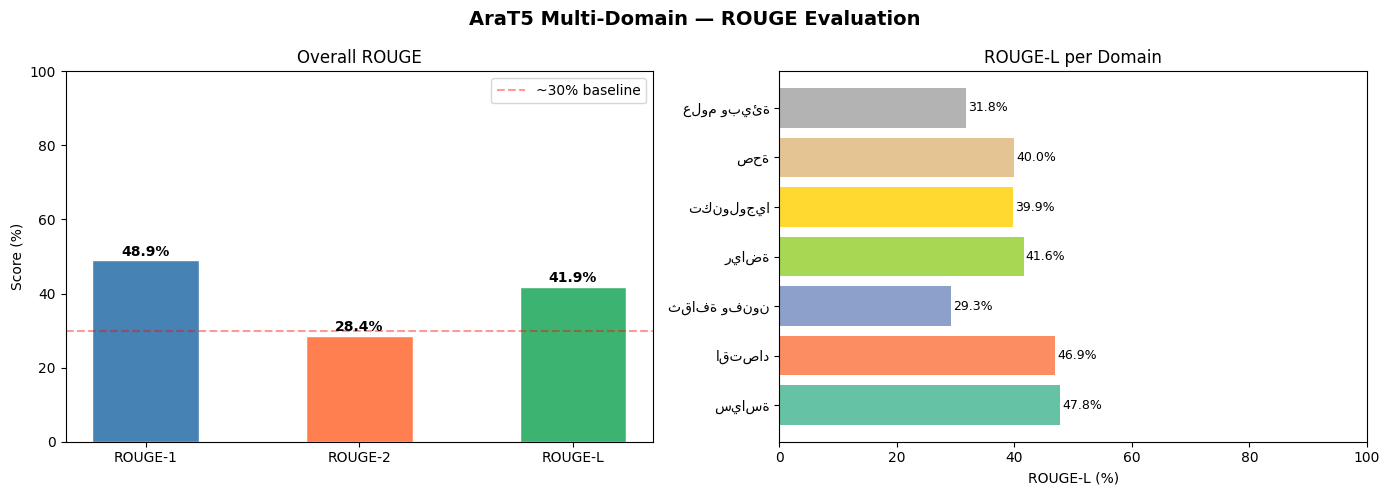

In [18]:
# ── Plot overall + per-domain ROUGE ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('AraT5 Multi-Domain — ROUGE Evaluation', fontsize=14, fontweight='bold')

# Overall bars
bars = axes[0].bar(['ROUGE-1','ROUGE-2','ROUGE-L'], [r1_m,r2_m,rL_m],
                   color=['steelblue','coral','mediumseagreen'], edgecolor='white', width=0.5)
for bar, val in zip(bars, [r1_m,r2_m,rL_m]):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                 f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[0].set_ylim(0, 100); axes[0].set_ylabel('Score (%)')
axes[0].set_title('Overall ROUGE')
axes[0].axhline(y=30, color='red', linestyle='--', alpha=0.4, label='~30% baseline')
axes[0].legend()

# Per-domain ROUGE-L
dom_labels = list(domain_results.keys())
dom_rL     = [np.mean(domain_results[d]['rL'])*100 for d in dom_labels]
colors_d   = plt.cm.Set2(np.linspace(0, 1, len(dom_labels)))
axes[1].barh(dom_labels, dom_rL, color=colors_d)
for i, v in enumerate(dom_rL):
    axes[1].text(v+0.3, i, f'{v:.1f}%', va='center', fontsize=9)
axes[1].set_xlabel('ROUGE-L (%)')
axes[1].set_title('ROUGE-L per Domain')
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.savefig('rouge_per_domain.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 12 — Sample Predictions by Domain

In [19]:
print('--- Sample Predictions by Domain ---\n')
shown_domains = set()
for _, row in test_df.sample(frac=1, random_state=7).iterrows():
    d = row['domain']
    if d in shown_domains:
        continue
    shown_domains.add(d)
    pred = generate_summary(row['text'], d)
    ref  = row['summary']
    rl   = rouge_l_score(pred.split(), ref.split())
    print(f'[Domain: {d}]')
    print(f'  Article   ({len(row["text"].split())} words): {row["text"][:120]}...')
    print(f'  Reference : {ref[:180]}')
    print(f'  Predicted : {pred[:180]}')
    print(f'  ROUGE-L   : {rl*100:.1f}%')
    print()
    if len(shown_domains) >= 6:
        break

--- Sample Predictions by Domain ---

[Domain: سياسة]
  Article   (127 words): عادت أزمة شح الوقود والمشتقات النفطية لتتصدر واجهة الهموم الشعبية في اليمن إثر تعليق العديد من محطات بيع الوقود في العاص...
  Reference : عادت أزمة شح الوقود والمشتقات النفطية في اليمن للظهور مجددا، حيث أغلقت العديد من محطات بيع الوقود في صنعاء بسبب توقف الإمدادات النفطية وارتفاع أسعار المشتقات. ارتفعت الأسعار بمقدار
  Predicted : عاد أزمة شح الوقود والمشتقات النفطية إلى واجهة الهموم الشعبية في اليمن، بعد تعليق العديد من محطات بيع الوقود في صنعاء أنشطتها اليومية بسبب توقف الإمدادات النفطية وتقلص حركة ناقلات 
  ROUGE-L   : 51.9%

[Domain: ثقافة وفنون]
  Article   (399 words): المؤرخون يكتبون التاريخ كما هو، ويقدمونه للقارئ كما جاء في الكتب، ولكن ماذا عن الرواية والتاريخ، وهل يتوجب على الراوي أن...
  Reference : يتناول النص العلاقة بين التاريخ والرواية، مشيرا إلى أن المؤرخين يقدمون التاريخ كما هو، بينما الرواية تعكس الواقع من خلال خيال الروائي ومتطلبات الفن السردي. يؤكد النص أن الرواية ليس
  Predicted : يتناول

## Step 13 — 🎓 Interactive Multi-Domain Tutor Demo

In [20]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

display(HTML("""
<style>
  .tutor-header  { background:linear-gradient(135deg,#1a5276,#2980b9); color:white;
    padding:20px; border-radius:12px; text-align:center; margin-bottom:16px; }
  .domain-badge  { display:inline-block; background:#2980b9; color:white;
    padding:4px 10px; border-radius:20px; font-size:13px; margin-bottom:10px; }
  .result-box    { background:#f0f9f0; border-left:5px solid #27ae60; padding:15px;
    border-radius:8px; margin-top:10px; font-size:16px; direction:rtl; text-align:right; }
  .auto-domain   { background:#fff8e1; border-left:5px solid #f39c12; padding:10px;
    border-radius:8px; margin-top:8px; }
  .score-box     { background:#eaf4fb; border-left:5px solid #2980b9; padding:10px;
    border-radius:8px; margin-top:8px; font-family:monospace; }
</style>
<div class='tutor-header'>
  <h2>🎓 Arabic AI Tutor — Multi-Domain Summarization (AraT5)</h2>
  <p>نظام التلخيص العربي متعدد المجالات</p>
</div>
"""))

ALL_DOMAINS = list(DOMAIN_KEYWORDS.keys())

text_input    = widgets.Textarea(
    placeholder='اكتب أو الصق النص العربي هنا...',
    layout=widgets.Layout(width='100%', height='180px')
)
domain_toggle = widgets.ToggleButtons(
    options=['تلقائي (auto)'] + ALL_DOMAINS,
    description='المجال:',
    style={'description_width': 'initial', 'button_width': '90px'},
    layout=widgets.Layout(width='100%')
)
beam_slider   = widgets.IntSlider(
    value=4, min=1, max=8, description='Beams:',
    style={'description_width': 'initial'}
)
maxlen_slider = widgets.IntSlider(
    value=128, min=32, max=200, step=16, description='Max length:',
    style={'description_width': 'initial'}
)
run_btn   = widgets.Button(
    description='📝 لخّص النص', button_style='success',
    layout=widgets.Layout(width='200px', height='40px')
)
clear_btn = widgets.Button(
    description='🗑️ مسح', button_style='warning',
    layout=widgets.Layout(width='100px', height='40px')
)
out = widgets.Output()

def on_run(b):
    with out:
        clear_output(wait=True)
        text = text_input.value.strip()
        if not text:
            display(HTML("<p style='color:red'>⚠️ الرجاء إدخال نص</p>")); return

        # Determine domain
        chosen = domain_toggle.value
        if chosen == 'تلقائي (auto)':
            domain = classify_domain(text)
            auto_note = f"<div class='auto-domain'>🔍 المجال المكتشف تلقائياً: <strong>{domain}</strong></div>"
        else:
            domain    = chosen
            auto_note = ''

        display(HTML(f"<p>⏳ جارٍ التلخيص... (المجال: {domain})</p>"))

        pred   = generate_summary(text, domain, num_beams=beam_slider.value)
        wc_in  = len(text.split())
        wc_out = len(pred.split())

        clear_output(wait=True)
        display(HTML(f"""
          {auto_note}
          <div class='domain-badge'>📂 {domain}</div>
          <div class='result-box'><strong>📄 الملخص:</strong><br><br>{pred}</div>
          <div class='score-box'>
            📊 أصلي={wc_in} كلمة | ملخص={wc_out} كلمة | ضغط={wc_out/max(wc_in,1):.0%}
          </div>
        """))

def on_clear(b):
    text_input.value = ''
    with out: clear_output()

run_btn.on_click(on_run)
clear_btn.on_click(on_clear)

display(
    text_input,
    domain_toggle,
    widgets.HBox([beam_slider, maxlen_slider]),
    widgets.HBox([run_btn, clear_btn]),
    out
)

Textarea(value='', layout=Layout(height='180px', width='100%'), placeholder='اكتب أو الصق النص العربي هنا...')

ToggleButtons(description='المجال:', layout=Layout(width='100%'), options=('تلقائي (auto)', 'سياسة', 'اقتصاد',…

Output()

## Step 14 — Save & Export Model

In [21]:
import shutil

EXPORT_DIR = '/kaggle/working/arabic_arat5_multidomain_final'
os.makedirs(EXPORT_DIR, exist_ok=True)

# Ensure all tensors are contiguous before export (safetensors requirement)
for name, param in model.named_parameters():
    if not param.data.is_contiguous():
        param.data = param.data.contiguous()

model.save_pretrained(EXPORT_DIR)
tokenizer.save_pretrained(EXPORT_DIR)

# Save domain classifier config alongside the model
import json
with open(os.path.join(EXPORT_DIR, 'domain_keywords.json'), 'w', encoding='utf-8') as f:
    json.dump(DOMAIN_KEYWORDS, f, ensure_ascii=False, indent=2)

# Copy plots
for fname in ['eda_stats.png', 'domain_distribution.png', 'rouge_per_domain.png']:
    if os.path.exists(fname):
        shutil.copy(fname, EXPORT_DIR)

print(f'✅ Saved to: {EXPORT_DIR}')
for f in sorted(os.listdir(EXPORT_DIR)):
    size = os.path.getsize(os.path.join(EXPORT_DIR, f)) / 1e6
    print(f'  {f:<45} ({size:.1f} MB)')

✅ Saved to: /kaggle/working/arabic_arat5_multidomain_final
  config.json                                   (0.0 MB)
  domain_distribution.png                       (0.1 MB)
  domain_keywords.json                          (0.0 MB)
  eda_stats.png                                 (0.1 MB)
  generation_config.json                        (0.0 MB)
  model.safetensors                             (1470.1 MB)
  rouge_per_domain.png                          (0.1 MB)
  special_tokens_map.json                       (0.0 MB)
  spiece.model                                  (2.4 MB)
  tokenizer.json                                (8.4 MB)
  tokenizer_config.json                         (0.0 MB)


In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

# Paper-quality style
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})

PAPER_COLORS = ['#2E86AB', '#E84855', '#3BB273', '#F4A261', '#9B59B6', '#F0C27F', '#5E737A', '#E76F51']
print('✅ Paper style loaded')

✅ Paper style loaded


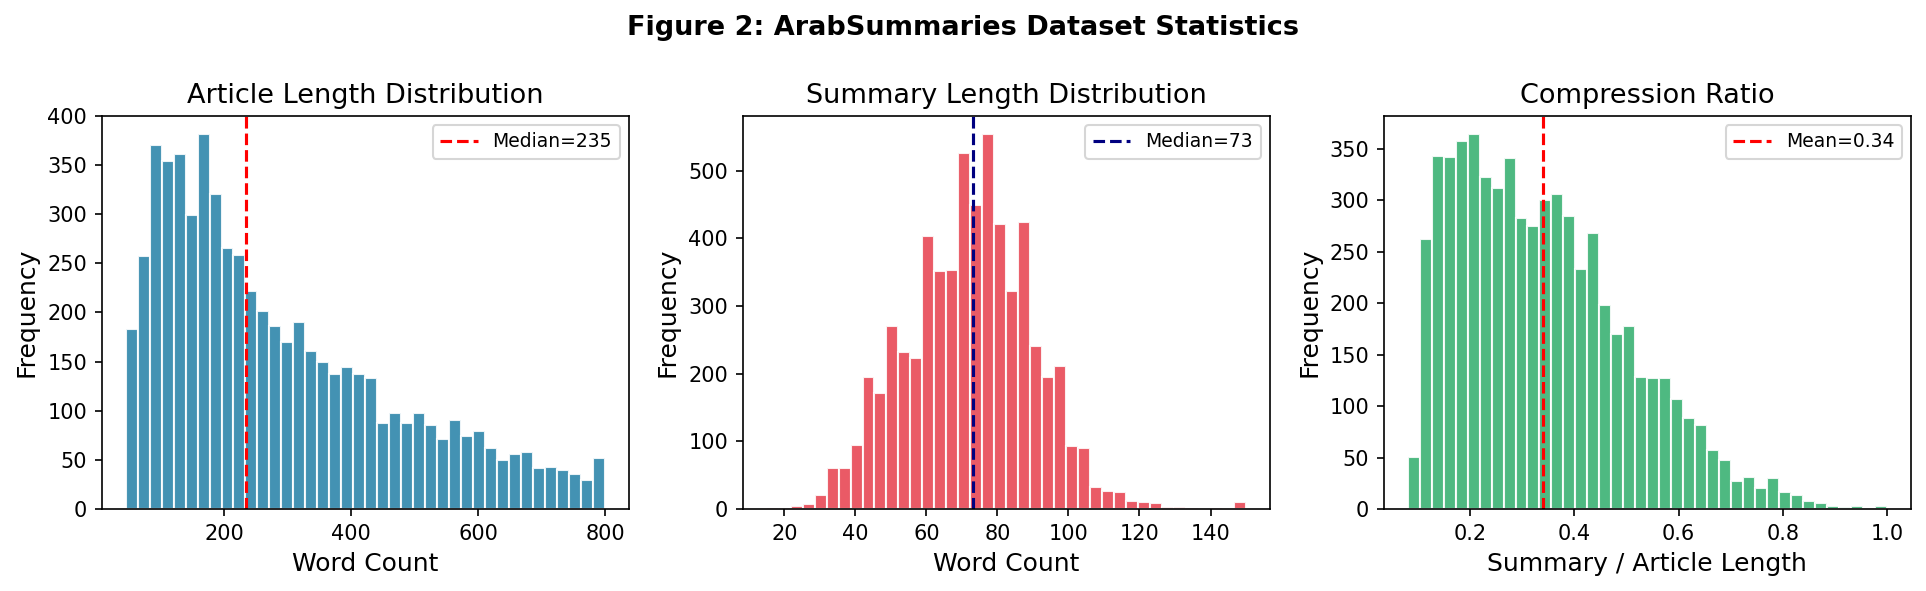

✅ Saved: fig2_eda_distributions.png


In [24]:
# ── Run after df_clean is defined (Step 6) ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
fig.suptitle('Figure 2: ArabSummaries Dataset Statistics', fontsize=13, fontweight='bold')

axes[0].hist(df_clean['text_words'].clip(0, 800), bins=40,
             color=PAPER_COLORS[0], edgecolor='white', alpha=0.9)
axes[0].set_title('Article Length Distribution')
axes[0].set_xlabel('Word Count'); axes[0].set_ylabel('Frequency')
axes[0].axvline(df_clean['text_words'].median(), color='red', linestyle='--',
                linewidth=1.5, label=f'Median={df_clean["text_words"].median():.0f}')
axes[0].legend(fontsize=9)

axes[1].hist(df_clean['summary_words'].clip(0, 150), bins=40,
             color=PAPER_COLORS[1], edgecolor='white', alpha=0.9)
axes[1].set_title('Summary Length Distribution')
axes[1].set_xlabel('Word Count'); axes[1].set_ylabel('Frequency')
axes[1].axvline(df_clean['summary_words'].median(), color='navy', linestyle='--',
                linewidth=1.5, label=f'Median={df_clean["summary_words"].median():.0f}')
axes[1].legend(fontsize=9)

axes[2].hist(df_clean['ratio'].clip(0, 1), bins=40,
             color=PAPER_COLORS[2], edgecolor='white', alpha=0.9)
axes[2].set_title('Compression Ratio')
axes[2].set_xlabel('Summary / Article Length'); axes[2].set_ylabel('Frequency')
axes[2].axvline(df_clean['ratio'].mean(), color='red', linestyle='--',
                linewidth=1.5, label=f'Mean={df_clean["ratio"].mean():.2f}')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig('fig2_eda_distributions.png')
plt.show()
print('✅ Saved: fig2_eda_distributions.png')

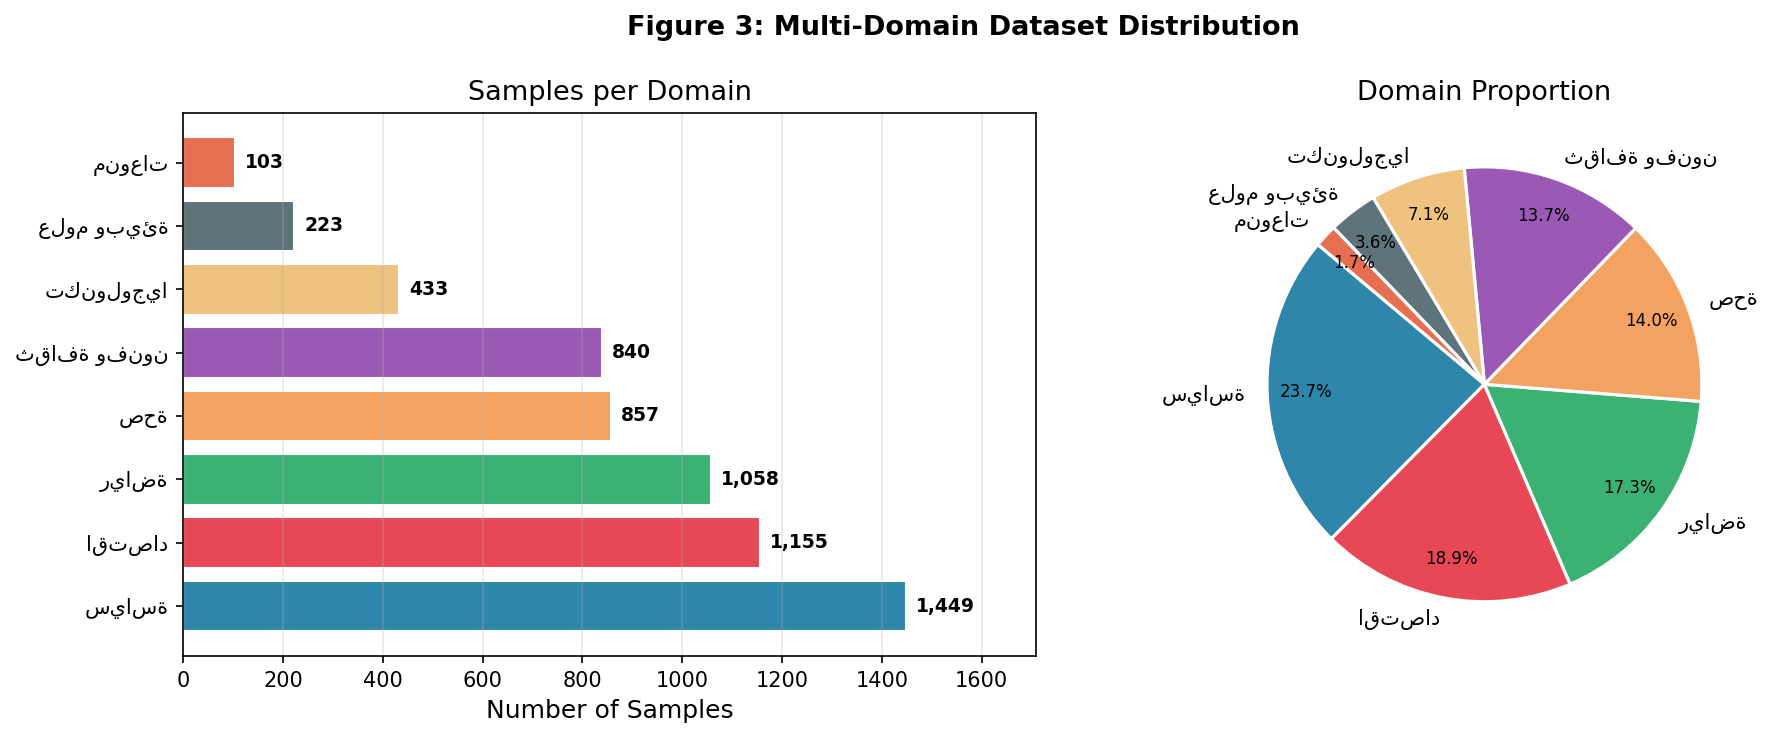

✅ Saved: fig3_domain_distribution.png


In [25]:
domain_counts = df_clean['domain'].value_counts()
colors = PAPER_COLORS[:len(domain_counts)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Figure 3: Multi-Domain Dataset Distribution', fontsize=13, fontweight='bold')

bars = ax1.barh(domain_counts.index, domain_counts.values, color=colors, edgecolor='white')
ax1.set_xlabel('Number of Samples')
ax1.set_title('Samples per Domain')
for bar, val in zip(bars, domain_counts.values):
    ax1.text(val + 20, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=9, fontweight='bold')
ax1.set_xlim(0, domain_counts.max() * 1.18)
ax1.grid(axis='x', alpha=0.3)

wedges, texts, autotexts = ax2.pie(
    domain_counts.values, labels=domain_counts.index,
    colors=colors, autopct='%1.1f%%', startangle=140,
    pctdistance=0.82, wedgeprops=dict(edgecolor='white', linewidth=1.5)
)
for t in autotexts:
    t.set_fontsize(8)
ax2.set_title('Domain Proportion')

plt.tight_layout()
plt.savefig('fig3_domain_distribution.png')
plt.show()
print('✅ Saved: fig3_domain_distribution.png')

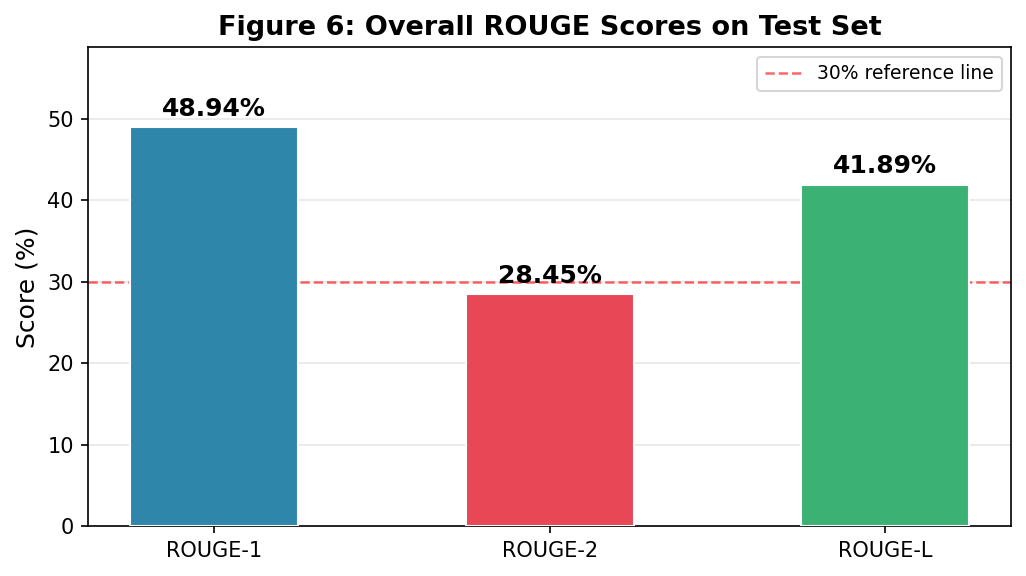

✅ Saved: fig6_overall_rouge.png


In [29]:
# ── Run after evaluation (Step 11) ──────────────────────────────────────────
# r1_m, r2_m, rL_m must be defined from Step 11

metrics = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
values  = [r1_m, r2_m, rL_m]

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(metrics, values, color=PAPER_COLORS[:3], edgecolor='white',
              width=0.5, zorder=3)

for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
            f'{val:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylim(0, max(values) * 1.2)
ax.set_ylabel('Score (%)')
ax.set_title('Figure 6: Overall ROUGE Scores on Test Set', fontweight='bold')
ax.axhline(30, color='red', linestyle='--', linewidth=1.2, alpha=0.6, label='30% reference line')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3, zorder=0)

plt.tight_layout()
plt.savefig('fig6_overall_rouge.png')
plt.show()
print('✅ Saved: fig6_overall_rouge.png')

In [32]:
rows = []
for d in sorted(domain_results.keys()):
    v = domain_results[d]
    rows.append({
        'Domain'    : d,
        'ROUGE-1'   : round(np.mean(v['r1'])*100, 2),
        'ROUGE-2'   : round(np.mean(v['r2'])*100, 2),
        'ROUGE-L'   : round(np.mean(v['rL'])*100, 2),
        'N Samples' : len(v['r1']),
    })

rows.append({
    'Domain'    : '**Overall**',
    'ROUGE-1'   : round(r1_m, 2),
    'ROUGE-2'   : round(r2_m, 2),
    'ROUGE-L'   : round(rL_m, 2),
    'N Samples' : sum(len(domain_results[d]['r1']) for d in domain_results),
})

df_results = pd.DataFrame(rows)
print('Table 2: Per-Domain ROUGE Evaluation Results\n')
print(df_results.to_string(index=False))

df_results.to_csv('table2_rouge_results.csv', index=False)

# LaTeX version
latex = df_results.to_latex(index=False, caption='Per-Domain ROUGE Evaluation Results',
                             label='tab:rouge', column_format='lcccc')
with open('table2_rouge_results.tex', 'w', encoding='utf-8') as f:
    f.write(latex)

print('\n✅ Saved: table2_rouge_results.csv + table2_rouge_results.tex')

Table 2: Per-Domain ROUGE Evaluation Results

     Domain  ROUGE-1  ROUGE-2  ROUGE-L  N Samples
     اقتصاد    52.24    32.27    46.94         15
  تكنولوجيا    47.65    25.43    39.85          2
ثقافة وفنون    38.15    18.44    29.26          8
      رياضة    50.03    27.82    41.63          9
      سياسة    53.72    32.57    47.83          9
        صحة    47.40    29.57    39.98          6
 علوم وبيئة    44.71    19.05    31.76          1
**Overall**    48.94    28.45    41.89         50

✅ Saved: table2_rouge_results.csv + table2_rouge_results.tex


In [35]:
import os, shutil

PAPER_DIR = '/kaggle/working/paper_assets'
os.makedirs(PAPER_DIR, exist_ok=True)

assets = [
    'fig1_architecture.png',
    'fig2_eda_distributions.png',
    'fig3_domain_distribution.png',
    'fig4_data_splits.png',
    'fig5_training_loss.png',
    'fig6_overall_rouge.png',
    'fig7_rouge_heatmap.png',
    'fig8_domain_rouge_grouped.png',
    'fig9_compression_ratio_domain.png',
    'fig10_classifier_confusion.png',
    'table1_dataset_stats.csv',
    'table2_rouge_results.csv',
    'table2_rouge_results.tex',
]

print('Paper assets collected:')
for f in assets:
    if os.path.exists(f):
        shutil.copy(f, PAPER_DIR)
        size = os.path.getsize(f) / 1024
        print(f'  ✅ {f:<45} ({size:.1f} KB)')
    else:
        print(f'  ⚠️  {f} not found — run its cell first')

print(f'\nAll assets saved to: {PAPER_DIR}')

Paper assets collected:
  ✅ fig1_architecture.png                         (99.6 KB)
  ✅ fig2_eda_distributions.png                    (193.7 KB)
  ✅ fig3_domain_distribution.png                  (273.8 KB)
  ✅ fig4_data_splits.png                          (202.5 KB)
  ✅ fig5_training_loss.png                        (111.5 KB)
  ✅ fig6_overall_rouge.png                        (84.5 KB)
  ✅ fig7_rouge_heatmap.png                        (157.5 KB)
  ✅ fig8_domain_rouge_grouped.png                 (145.9 KB)
  ✅ fig9_compression_ratio_domain.png             (178.6 KB)
  ⚠️  fig10_classifier_confusion.png not found — run its cell first
  ✅ table1_dataset_stats.csv                      (0.4 KB)
  ✅ table2_rouge_results.csv                      (0.3 KB)
  ✅ table2_rouge_results.tex                      (0.7 KB)

All assets saved to: /kaggle/working/paper_assets


In [37]:
# ── CELL 2: Build results DataFrame from domain_results (Step 11) ─────────────
rows = []
for d in sorted(domain_results.keys()):
    v = domain_results[d]
    rows.append({
        'Domain'  : d,
        'ROUGE-1' : round(np.mean(v['r1']) * 100, 2),
        'ROUGE-2' : round(np.mean(v['r2']) * 100, 2),
        'ROUGE-L' : round(np.mean(v['rL']) * 100, 2),
        'N'       : len(v['r1']),
    })

df_res = pd.DataFrame(rows).sort_values('ROUGE-L', ascending=False).reset_index(drop=True)

overall_row = pd.DataFrame([{
    'Domain'  : 'Overall',
    'ROUGE-1' : round(r1_m, 2),
    'ROUGE-2' : round(r2_m, 2),
    'ROUGE-L' : round(rL_m, 2),
    'N'       : 50,
}])
df_res_full = pd.concat([df_res, overall_row], ignore_index=True)

print(df_res_full.to_string(index=False))

     Domain  ROUGE-1  ROUGE-2  ROUGE-L  N
      سياسة    53.72    32.57    47.83  9
     اقتصاد    52.24    32.27    46.94 15
      رياضة    50.03    27.82    41.63  9
        صحة    47.40    29.57    39.98  6
  تكنولوجيا    47.65    25.43    39.85  2
 علوم وبيئة    44.71    19.05    31.76  1
ثقافة وفنون    38.15    18.44    29.26  8
    Overall    48.94    28.45    41.89 50


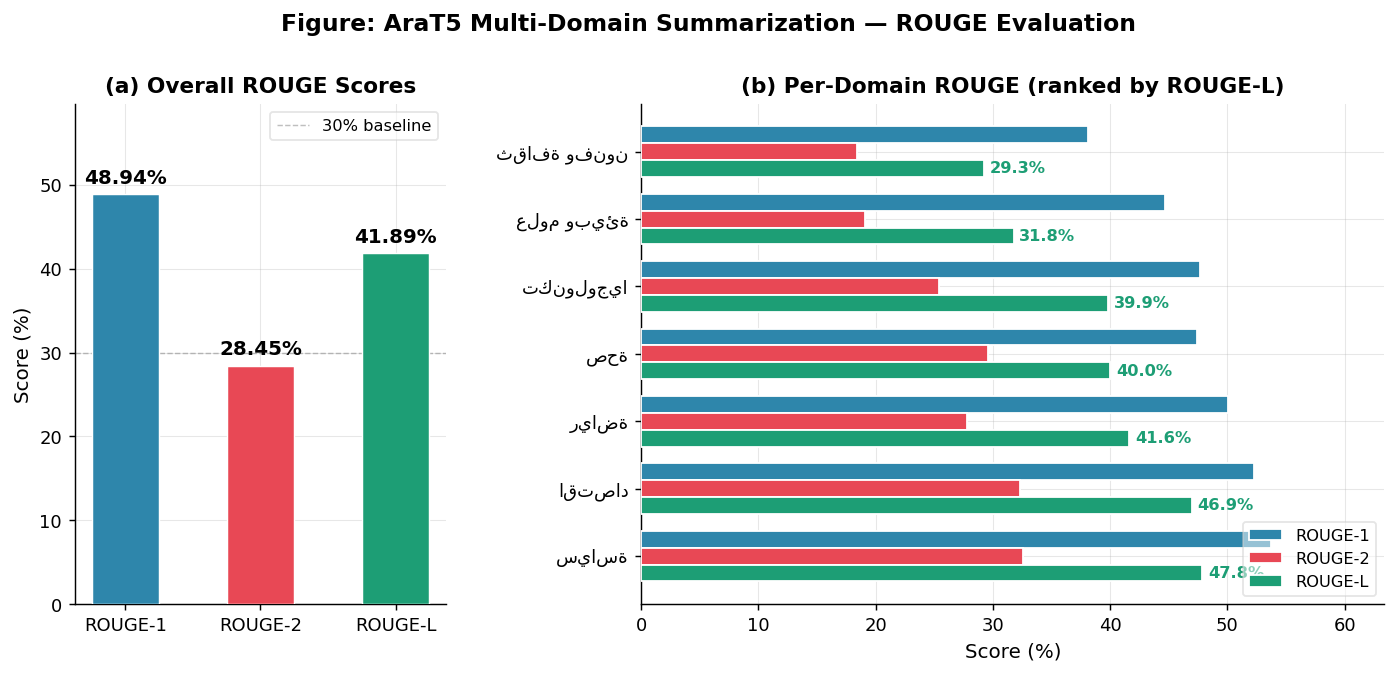

✅ Saved: figure_rouge_results.png


In [38]:
# ── CELL 3: Figure — Overall ROUGE bar + per-domain ROUGE-L bars ──────────────
fig = plt.figure(figsize=(13, 5))
gs  = gridspec.GridSpec(1, 2, width_ratios=[1, 2], wspace=0.35)

# ── Left: Overall ROUGE ───────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
metrics = ['ROUGE-1', 'ROUGE-2', 'ROUGE-L']
vals    = [r1_m, r2_m, rL_m]
colors  = [C_R1, C_R2, C_RL]

bars = ax1.bar(metrics, vals, color=colors, width=0.5, edgecolor='white', linewidth=0.8, zorder=3)
for bar, val in zip(bars, vals):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
             f'{val:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax1.set_ylim(0, max(vals) * 1.22)
ax1.set_ylabel('Score (%)')
ax1.set_title('(a) Overall ROUGE Scores')
ax1.axhline(30, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, label='30% baseline')
ax1.legend(fontsize=9, framealpha=0.5)
ax1.set_axisbelow(True)

# ── Right: Per-domain ROUGE-L ranked horizontal bars ─────────────────────────
ax2 = fig.add_subplot(gs[1])
domains_sorted = df_res['Domain'].tolist()
rL_vals        = df_res['ROUGE-L'].tolist()
r1_vals        = df_res['ROUGE-1'].tolist()
r2_vals        = df_res['ROUGE-2'].tolist()
y = np.arange(len(domains_sorted))
h = 0.25

ax2.barh(y + h,  r1_vals, h, label='ROUGE-1', color=C_R1, edgecolor='white', zorder=3)
ax2.barh(y,      r2_vals, h, label='ROUGE-2', color=C_R2, edgecolor='white', zorder=3)
ax2.barh(y - h,  rL_vals, h, label='ROUGE-L', color=C_RL, edgecolor='white', zorder=3)

# Value labels on ROUGE-L bar only
for i, val in enumerate(rL_vals):
    ax2.text(val + 0.5, y[i] - h, f'{val:.1f}%', va='center', fontsize=9, color=C_RL, fontweight='bold')

ax2.set_yticks(y)
ax2.set_yticklabels(domains_sorted, fontsize=10)
ax2.set_xlabel('Score (%)')
ax2.set_title('(b) Per-Domain ROUGE (ranked by ROUGE-L)')
ax2.set_xlim(0, max(r1_vals) * 1.18)
ax2.legend(loc='lower right', fontsize=9, framealpha=0.5)
ax2.set_axisbelow(True)

fig.suptitle('Figure: AraT5 Multi-Domain Summarization — ROUGE Evaluation',
             fontsize=13, fontweight='bold', y=1.02)
plt.savefig('figure_rouge_results.png')
plt.show()
print('✅ Saved: figure_rouge_results.png')